# Singular Value Decomposition

**Theorem:** Let $A$ be any $b\times n$ matrix. There exists $U, \Sigma, V$ such that
$$
A = U*\Sigma * V^T,
$$
where $U$ is $m\times m$ orthogonal matrix (rotation), $V$ is an $n\times n$ orthogonal matrix, and $\Sigma$ is the diagonal matrix that haas the same size as $A$.

## Eigenvalues and eigenvectors

Let $A$ be a square matrix and $x$ is a vector such that
$$
Ax = \lambda x,
$$
then $x$ is called an eigenvector, and $\lambda$ is called an eigenvalue.

Use `Numpy` to find the eigenvalues and eigenvectors od any square matrix.

- Generate a random square matrix with integers
- USe Numpy to calculate the eigenvalues and also the eigenvectors.

In [1]:
import numpy as np

In [2]:
n = 5
A = np.random.randint(low=-3, high=3, size=(n, n))

In [3]:
A

array([[ 0,  0,  0, -1,  1],
       [-1,  2,  1,  1, -2],
       [-2, -1, -3,  2,  0],
       [ 2, -3,  1, -1, -3],
       [-1, -1,  0,  0, -2]])

In [4]:
# compute the eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(A)

In [5]:
print(eigenvalues)

[ 0.38802272+1.79658852j  0.38802272-1.79658852j  0.79128785+0.j
 -1.77604544+0.j         -3.79128785+0.j        ]


**Theorem:** If $A$ is a symmetric matrix, then it's eigenvalues are real. ($A$ is symmetric if $A=A^T$)

In [6]:
# function the generate symmetric matrix
def gen_sym_mat(n, low=-3, high=4):
    B = np.random.randint(low=low, high=high, size=(n, n))
    A = B@B.T
    return A

In [7]:
A = gen_sym_mat(5)

In [8]:
A

array([[ 3, -1, -1,  4,  0],
       [-1, 14,  2,  6, 17],
       [-1,  2, 10,  3, 12],
       [ 4,  6,  3, 35, 10],
       [ 0, 17, 12, 10, 32]])

In [9]:
# compute the eigen values, vectors
eig_vals, eig_vecs = np.linalg.eig(A)

In [10]:
print(eig_vals)

[5.36612679e+01+0.j 2.78413934e+01+0.j 3.09328705e-02+0.j
 2.94545661e+00+0.j 9.52094929e+00+0.j]


In [11]:
print(eig_vecs)

[[ 0.03048897+0.j -0.1502595 +0.j  0.43631614+0.j  0.88662216+0.j
  -0.00467609+0.j]
 [ 0.39300607+0.j  0.23478262+0.j  0.5579356 +0.j -0.24487646+0.j
   0.64743088+0.j]
 [ 0.24638339+0.j  0.19874794+0.j  0.51963868+0.j -0.2345081 +0.j
  -0.75813988+0.j]
 [ 0.54599985+0.j -0.8247812 +0.j -0.05446941+0.j -0.13193599+0.j
  -0.03530038+0.j]
 [ 0.6969907 +0.j  0.45003826+0.j -0.47470498+0.j  0.28554422+0.j
  -0.0692041 +0.j]]


Notice: eigenvectors are column vectors in `eigen_vecs` matrix.

In [12]:
# Check these eigenvectors and eigenvelues
lamb1 = eig_vals[0]
print(lamb1)

(53.6612678599234+0j)


In [13]:
vec1 = eig_vecs[:,0]
print(vec1)

[0.03048897+0.j 0.39300607+0.j 0.24638339+0.j 0.54599985+0.j
 0.6969907 +0.j]


In [14]:
# check A*vec1 = lamb1 * vec1?
np.allclose(A @ vec1, lamb1 * vec1)

True

In [15]:
# the order matters as we swap the order, we don't have the eigen values for that vector
vec2 = eig_vecs[:,2]
# vec2 is not an eigenvector associated to lamb1
np.allclose(A @ vec2, lamb1 * vec2)

False

**Question:** How to find the eigenvalue and eigenvector of a matrix numerically?

## The Power Method to find the eigenvalue and eigenvector.
**Dominant eigenvalue:** Suppose $A$ has $n$ eigenvalues $\lambda_1, \lambda_2, \ldots, \lambda_n.$
The $\lambda_1$ is caled a dominant eigenvalue if
$$
|\lambda_1| > |\lambda_j|
$$
for any $j=2,3,\ldots,n$.

**Theorem:** (Power Method) Let $A$ be a diagonalizable $n\times n$ matrix with eigenvalues
$$
|\lambda_1| \gt |\lambda_2| \ge |\lambda_3| \ge \cdots \ge |\lambda_n|.
$$
Pick any vector $x_0$ and define
$$
y_{k+1} = Ax_k, \quad x_{k+1} = \frac{y_{k+1}}{\|y_{k+1}\|}.
$$
- Then $x_k$ converges to an eigenvector.
- The Rayleigh quotient
$$
- \mu_k = x_k^T*A*x_k\to \lambda_1
$$

In [16]:
import numpy as np

In [17]:
# write a function to return eigen the dominant eigenvector and eigenvalue
# is algorithm converged?
# how many iterations do we need to get the eigen vector
# error during the approximation
# return the eigenvalue and eigenvector
def power_method(A, x0, tol=1e-10, max_iters=1000):
    """
    x0: initial vector
    tol: the error to stop
    max_iters:  the number of iterations
    """
    x = x0 / np.linalg.norm(x0) # normalize to get norm 1
    # create some arrays to keep track of the error
    errors = []
    converged = False
    lamb = None # for last eigenvalue
    x = A @ x0
    for i in range(max_iters):
        y = A @ x
        lamb = x @ y
        err = np.linalg.norm(y - lamb * x)
        errors.append(err)
        # stop if small error
        if err < tol:
            converged = True
            print(f"Algorithm converges at step {i+1}th")
            break # break the loop

        # we cannot go longer if y near zero!
        y_norm = np.linalg.norm(y)
        if y_norm == 0:
            break

        # update x for the next iteration
        else:
            x = y / y_norm

    return lamb, x, converged, errors

In [18]:
# test the algorithm
A1 = np.array([
    [2, 1],
    [1, 3]
])

In [19]:
# create a random vector x0 to start
x0 = np.random.normal(loc=0, scale=1, size=2)

In [20]:
lamb, x, converged, errors = power_method(A1, x0)

Algorithm converges at step 24th


In [21]:
print(lamb)
print(x)

3.6180339887498945
[0.52573111 0.85065081]


In [22]:
# test 3x3 matrix
A2 = np.array([
    [1, 2, 0],
    [3, -4, 1],
    [0, 1, 2]
])

In [23]:
x0 = np.random.normal(loc=0, scale=1, size=3)
lamb, x, converged, errors = power_method(A2, x0)

Algorithm converges at step 35th


## The complexity of the Power method

**Theorem:** If $\lambda_1$ is the dominant eigenvalue of $A$ and
$$
|\lambda_1| \gt |\lambda_2| \ge \cdots \ge |\lambda_n|
$$
then the errors of the Power method is about $O(|\frac{\lambda_2}{\lambda_1}|^k)$

Notice
$$
\lim_{k\to\infty} q^k = 0
$$
where $0 \lt q \lt 1$.

Use Python to demonstrate the complexity of the error of the Power method.

In [24]:
A2

array([[ 1,  2,  0],
       [ 3, -4,  1],
       [ 0,  1,  2]])

In [25]:
# use A2 to test the convergence of the error at speed |lambda_2/lambda_1|^k.
# check the eigenvalues of A2
np.linalg.eigvals(A2)

array([-5.12071328+0.j,  1.68078017+0.j,  2.4399331 +0.j])

In [26]:
# sort the eigenvalues by magnitude
eigen_vals = np.linalg.eigvals(A2)

In [27]:
sorted_idx = np.argsort(-1.0 * np.abs(eigen_vals))

In [28]:
print(sorted_idx)

[0 2 1]


In [29]:
sorted_eigen_vals = eigen_vals[sorted_idx]

In [30]:
sorted_eigen_vals

array([-5.12071328+0.j,  2.4399331 +0.j,  1.68078017+0.j])

In [31]:
lamb1 = sorted_eigen_vals[0]
lamb2 = sorted_eigen_vals[1]

By theorem, we have
$$
error(k) = C\frac{|\lambda_2|}{|\lambda_1|}^k
$$

Then
$$
\ln(error(k)) = \ln(X) + k*\ln(\frac{|\lambda_2|}{|\lambda_1|})
$$

In [32]:
x0 = np.random.normal(loc=0, scale=1, size=3)
lamb, x, converged, errors = power_method(A2, x0)

Algorithm converges at step 33th


In [33]:
k_vals = np.arange(1, len(errors) + 1)

In [34]:
k_vals

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33])

In [35]:
import matplotlib.pyplot as plt

In [36]:
# compute the intercept from actual data
_, intercept = np.polyfit(k_vals, np.log(errors), deg=1)
print(intercept)

1.732431082034425


In [37]:
# theoretical slope
ratio = np.abs(lamb2/lamb1)
print(ratio)

0.4764830546336143


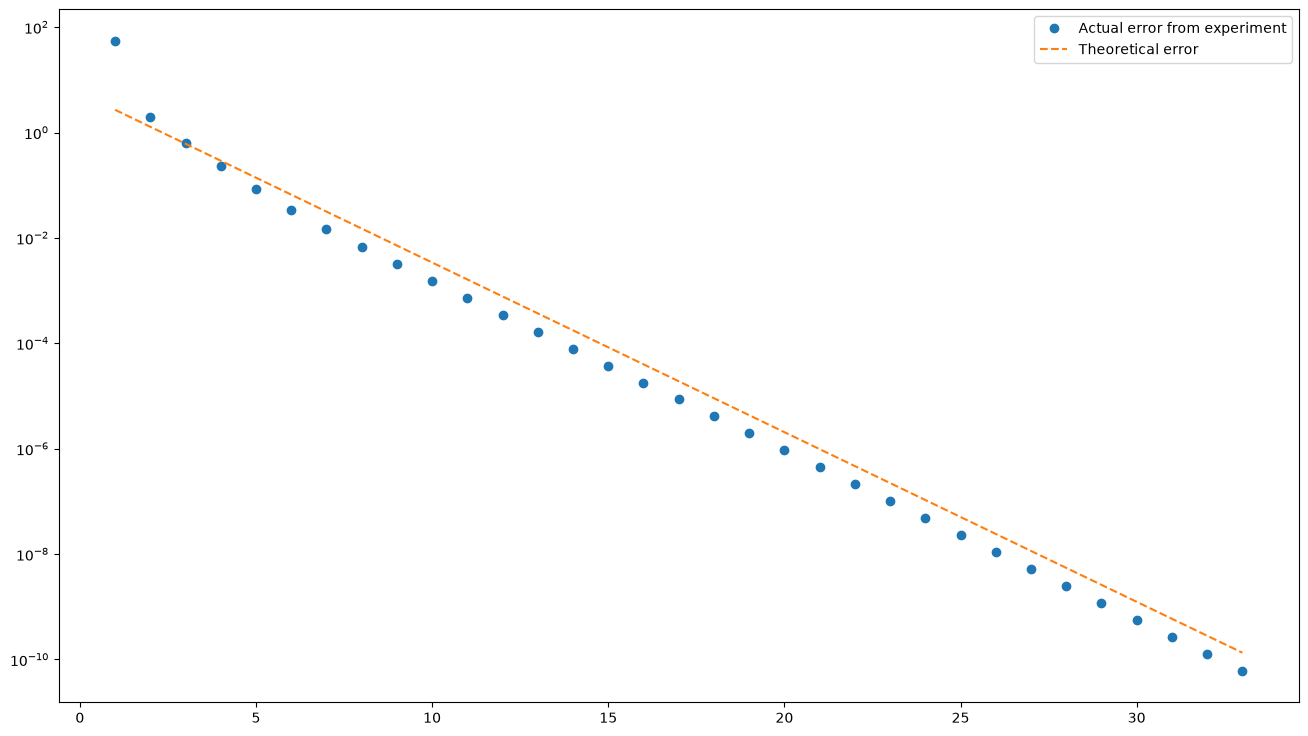

In [38]:
# plot the error first: k is normal, but take ln(errors)
fix, ax = plt.subplots(figsize=(16, 9))

# keep k values, but take log(error), use semilog(y)
ax.semilogy(k_vals, errors, "o", label="Actual error from experiment")
# same as ax.plot(k_vals, np.log(errors))

# plo the theoretical line for the error
#ax.semilogy(k_vals, intercept + k_vals * np.log(ratio), "-", label="Theoretical error")

ax.semilogy(k_vals, np.exp(intercept)* ratio**k_vals, "--", label="Theoretical error")

ax.legend()
plt.show()

# Implementation of SVD

Any matrix $A$ we can write $A=U*\Sigma*V^T$, where
- $U$ is the left singular vectors: $U*U^T = I_m$
- $V$ is the right singular vectors: $V*V^T = I_n$.
- $\Sigma$ has the same size as $A$, but have singular values $\sigma_i$ on the diagonal.

## Construct $U$ and $\Sigma$

From $A = U*\sigma*V^T$, we have
$$
A*A^T = (U*\sigma*V^T)*(U*\sigma*V^T)^T = (U*\sigma*V^T)*(V*\Sigma^T*U^T)
$$

So $U$ is the eigenvectors of the matrix $A*A^T$ ($A$ is on the left side!) and $\sigma_i = \sqrt{\lambda_i}$, where $\lambda_i$ is the eigen values of $A*A^T$.

$U$ and $V$ are related in the following equation
$$
A^T*u_i = \sigma_i*v_i.
$$

**Example:** Generate a random matrix, then find $U$ and $\Sigma$ in the SVD of $A$.

In [39]:
import numpy as np
import matplotlib.pyplot as plt

In [40]:
A = np.random.randint(low=-3, high=3, size=(4, 5))
print(A)

[[-1  0 -2  0 -3]
 [ 0 -2 -2  0  2]
 [-2  0  2 -2  2]
 [-3  1  0 -3 -1]]


In [41]:
# to get the left singular vectors, compute A*A^T
L = A@A.T

In [42]:
print(L)

[[14 -2 -8  6]
 [-2 12  0 -4]
 [-8  0 16 10]
 [ 6 -4 10 20]]


In [43]:
# find eigenvalues and eigenvectors
eig_vals, eig_vecs = np.linalg.eig(L)

In [44]:
print(eig_vals)

[ 0.37516745+0.j 10.58485794+0.j 22.25804558+0.j 28.78192903+0.j]


In [45]:
print(eig_vecs)

[[-0.58231975+0.j -0.26820659+0.j -0.76723682+0.j  0.01779309+0.j]
 [ 0.07623028+0.j -0.9421139 +0.j  0.26712737+0.j -0.18775866+0.j]
 [-0.62628302+0.j -0.02836919+0.j  0.49912814+0.j  0.59819384+0.j]
 [ 0.51270092+0.j -0.19920295+0.j -0.30143279+0.j  0.77884159+0.j]]


**Notice:** The order of the eigenvectors are correspondingly to the order of the eigenvalues. So if we change the order of eigenvalues, we have to chanage the order of the eigenvectors.

In [46]:
# re-arrange the eigenvalues in decreasing order
# 3.79993848  5.75092199 22.83875854 34.61038099 not decreasing!
sorted_idx = np.argsort(-eig_vals)

In [47]:
sorted_idx

array([3, 2, 1, 0])

In [48]:
sorted_eigen_vals = eig_vals[sorted_idx]
print(sorted_eigen_vals)

[28.78192903+0.j 22.25804558+0.j 10.58485794+0.j  0.37516745+0.j]


In [49]:
sorted_eigen_vecs = eig_vecs[:, sorted_idx]

In [50]:
print(sorted_eigen_vecs)

[[ 0.01779309+0.j -0.76723682+0.j -0.26820659+0.j -0.58231975+0.j]
 [-0.18775866+0.j  0.26712737+0.j -0.9421139 +0.j  0.07623028+0.j]
 [ 0.59819384+0.j  0.49912814+0.j -0.02836919+0.j -0.62628302+0.j]
 [ 0.77884159+0.j -0.30143279+0.j -0.19920295+0.j  0.51270092+0.j]]


In [51]:
# Construct U
U = sorted_eigen_vecs

In [52]:
# Construct the Sigma
S = np.zeros_like(A).astype(float)

In [53]:
# fill the sqrt of sorted_eigen_vals on the diagonal
for i in range(min(A.shape)):
    S[i,i] = np.sqrt(sorted_eigen_vals[i])

/var/folders/_b/zt2whyhx3n906g8v4hwq50hw0000gn/T/ipykernel_7288/2069590970.py:3: ComplexWarning: Casting complex values to real discards the imaginary part
  S[i,i] = np.sqrt(sorted_eigen_vals[i])


In [54]:
print(S)

[[5.36487922 0.         0.         0.         0.        ]
 [0.         4.71784332 0.         0.         0.        ]
 [0.         0.         3.25343787 0.         0.        ]
 [0.         0.         0.         0.61250914 0.        ]]


## Construct the right singular vectors. $V$

In [55]:
# compute the R matrix (A is on the right side)
R = A.T @ A

In [56]:
print(R)

[[14 -3 -2 13  2]
 [-3  5  4 -3 -5]
 [-2  4 12 -4  6]
 [13 -3 -4 13 -1]
 [ 2 -5  6 -1 18]]


In [57]:
# compute the eigenvalues and eigenvector for R
right_vals, right_vecs = np.linalg.eig(R)

In [58]:
print(right_vals)

[ 2.87819290e+01+0.j  2.22580456e+01+0.j  1.05848579e+01+0.j
 -1.14889532e-15+0.j  3.75167447e-01+0.j]


In [59]:
# sort the right values
sorted_right_idx = np.argsort(-right_vals)
print(sorted_right_idx)

[0 1 2 4 3]


In [60]:
# re-arrange the right vectors
sorted_right_vecs = right_vecs[:, sorted_right_idx]

In [61]:
# build the matrix V from sorted_right_vecs
right_singular_vecs = []
m, n = A.shape
for i in range(n):
    # make sure A^T*u_i = \sigma_i*v_i
    v_i = sorted_right_vecs[:,i]
    if i < m:
        s_i = S[i, i]
        u_i = U[:, i]
        # print(np.allclose(A.T@u_i, s_i*v_i))
        # print(A.T@u_i, s_i*v_i)
        if np.allclose(A.T@u_i, s_i*v_i):
            right_singular_vecs.append(v_i)
        else:
            right_singular_vecs.append(-1.0 * v_i)
    else:
        right_singular_vecs.append(v_i)

In [62]:
right_singular_vecs

[array([-0.66184259+0.j,  0.2151696 +0.j,  0.28636597+0.j, -0.658526  +0.j,
        -0.0021157 +0.j]),
 array([ 0.14270904+0.j, -0.17713338+0.j,  0.42359931+0.j, -0.01991544+0.j,
         0.87659848+0.j]),
 array([ 0.28356277-0.j,  0.51792132-0.j,  0.72658606-0.j,  0.20112486-0.j,
        -0.28804713+0.j]),
 array([ 0.48453646+0.j,  0.58813877+0.j, -0.39246284+0.j, -0.46617547+0.j,
         0.2190218 +0.j]),
 array([ 0.47583095+0.j, -0.55513611+0.j,  0.23791548+0.j, -0.55513611+0.j,
        -0.31722063+0.j])]

In [63]:
VT = np.array(right_singular_vecs)

In [64]:
V = VT.T

In [65]:
# check A = U * S * VT
np.allclose(A, U @ (S @ VT))

True

In [66]:
# write svd function
def svd(A):
    # return U, S, VT
    m, n = A.shape
    # compute L (A on the left)
    L = A @ A.T
    leigen_vals, leigen_vecs = np.linalg.eig(L)
    left_idx = np.argsort(-leigen_vals)
    sorted_vals = leigen_vals[left_idx]
    U = leigen_vecs[:, left_idx]
    # build S
    S = np.zeros_like(A).astype(float)
    for i in range(min(m,n)):
        S[i,i] = np.sqrt(sorted_vals[i])

    # build the matrix VT
    R = A.T @ A
    reigen_vals, reigen_vecs = np.linalg.eig(R)
    right_idx = np.argsort(-reigen_vals)
    # sort the right vector
    sorted_right_vecs = reigen_vecs[:, right_idx]
    # loop and build VT
    vectors = []
    for i in range(n):
        v_i = sorted_right_vecs[:, i]
        if i < m:
            u_i = U[:, i]
            s_i = S[i, i]
            if np.allclose(A.T@u_i, s_i*v_i):
                vectors.append(v_i)
            else:
                vectors.append(-v_i)
        else:
            vectors.append(v_i)

    return U, S, np.array(vectors)